# **<div align="center">TARGET DEFINITION</div>**

Subtitle

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **Initial Configuration**

In [97]:
HORIZONS = {
    "short": 7,
    "medium": 21,
    "long": 50
}

CRYPTO_NAMES = [
    "bitcoin",
    "ethereum",
    "tether",
    "binancecoin",
    "usd-coin"
]

DATA_PATH = "../data/processed/"

TRAIN_RATIO = 0.8

RETURN_THRESHOLDS = {
    "short": 0.03,
    "medium": 0.05,
    "long": 0.08
}

In [98]:
def classify_trend(ratio):
    if pd.isna(ratio):
        return np.nan
    elif ratio <= -2:
        return -2
    elif ratio < -1:
        return -1
    elif ratio < 1:
        return 0
    elif ratio < 2:
        return 1
    else:
        return 2

In [99]:
def classify_ratio(ratio):
    if pd.isna(ratio):
        return np.nan
    elif ratio <= -2:
        return -2
    elif ratio <= -1:
        return -1
    elif ratio < 1:
        return 0
    elif ratio < 2:
        return 1
    else:
        return 2

In [100]:
def classify_trend(ratio):
    if pd.isna(ratio):
        return np.nan
    elif ratio <= -2:
        return -2
    elif ratio < -1:
        return -1
    elif ratio < 1:
        return 0
    elif ratio < 2:
        return 1
    else:
        return 2

In [101]:
def classify_trend_3(ratio):
    if pd.isna(ratio) or not np.isfinite(ratio):
        return np.nan
    elif ratio <= -1:
        return -1
    elif ratio < 1:
        return 0
    else:
        return 1

In [102]:
def classify_return_3(return_value, threshold):
    if pd.isna(return_value):
        return np.nan
    elif return_value <= -threshold:
        return -1
    elif return_value < threshold:
        return 0
    else:
        return 1

## **Import dataset**

In [103]:
dfs = {}

for crypto in CRYPTO_NAMES:
    path = f"{DATA_PATH}{crypto}.csv"
    
    df = pd.read_csv(path)
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date", drop=False).sort_index()
    
    dfs[crypto] = df

    print(
        f"{crypto}: "
        f"{len(df)} observations | "
        f"{df.index.min().date()} -> {df.index.max().date()}"
    )

bitcoin: 281 observations | 2025-02-05 -> 2025-11-12
ethereum: 241 observations | 2025-02-05 -> 2025-10-03
tether: 281 observations | 2025-02-05 -> 2025-11-12
binancecoin: 240 observations | 2025-02-05 -> 2025-10-02
usd-coin: 280 observations | 2025-02-06 -> 2025-11-12


In [104]:
for crypto, df in dfs.items():
    print(f"\n{crypto}")
    display(df.head())


bitcoin


,cryptocurrency_id,price_usd,market_cap,volume,date
date,,,,,
2025-02-05,1.0,97864.0,1.940960e+12,6.365740e+10,2025-02-05
2025-02-06,1.0,99038.0,1.960400e+12,4.243940e+10,2025-02-06
2025-02-07,1.0,97683.0,1.932660e+12,4.612790e+10,2025-02-07
2025-02-08,1.0,97683.0,1.932660e+12,4.612790e+10,2025-02-08
2025-02-09,1.0,97683.0,1.932660e+12,4.612790e+10,2025-02-09



ethereum


,cryptocurrency_id,price_usd,market_cap,volume,date
date,,,,,
2025-02-05,2.0,2780.50,3.352540e+11,4.421130e+10,2025-02-05
2025-02-06,2.0,2825.73,3.408410e+11,3.054070e+10,2025-02-06
2025-02-07,2.0,2753.45,3.318870e+11,3.019830e+10,2025-02-07
2025-02-08,2.0,2753.45,3.318870e+11,3.019830e+10,2025-02-08
2025-02-09,2.0,2753.45,3.318870e+11,3.019830e+10,2025-02-09



tether


,cryptocurrency_id,price_usd,market_cap,volume,date
date,,,,,
2025-02-05,3.0,1.0,1.405310e+11,1.073240e+11,2025-02-05
2025-02-06,3.0,1.0,1.412260e+11,8.110920e+10,2025-02-06
2025-02-07,3.0,1.0,1.414070e+11,6.782090e+10,2025-02-07
2025-02-08,3.0,1.0,1.414070e+11,6.782090e+10,2025-02-08
2025-02-09,3.0,1.0,1.414070e+11,6.782090e+10,2025-02-09



binancecoin


,cryptocurrency_id,price_usd,market_cap,volume,date
date,,,,,
2025-02-05,4.0,571.03,8.327530e+10,1.241400e+09,2025-02-05
2025-02-06,4.0,580.05,8.457820e+10,4.711890e+08,2025-02-06
2025-02-07,4.0,586.11,8.556300e+10,1.075490e+09,2025-02-07
2025-02-08,4.0,586.11,8.556300e+10,1.075490e+09,2025-02-08
2025-02-09,4.0,586.11,8.556300e+10,1.075490e+09,2025-02-09



usd-coin


,cryptocurrency_id,price_usd,market_cap,volume,date
date,,,,,
2025-02-06,5.0,1.00000,5.554900e+10,1.122790e+10,2025-02-06
2025-02-07,5.0,0.99999,5.574810e+10,1.090440e+10,2025-02-07
2025-02-08,5.0,0.99999,5.574810e+10,1.090440e+10,2025-02-08
2025-02-09,5.0,0.99999,5.574810e+10,1.090440e+10,2025-02-09
2025-02-10,5.0,0.99995,5.627930e+10,8.631850e+09,2025-02-10


## **1. Calculate price target for each horizon**

In [105]:
for crypto, df in dfs.items():

    for horizon_name, horizon in HORIZONS.items():

        df[f"target_price_{horizon_name}"] = (
            df["price_usd"].shift(-horizon)
        )

## **2. Calculate future returns**

In [106]:
for crypto, df in dfs.items():
    
    for name, horizon in HORIZONS.items():
        df[f"future_return_{name}"] = (
            df["price_usd"].shift(-horizon)
            / df["price_usd"]
            - 1
        )

In [107]:
dfs["bitcoin"][
    [
        "price_usd",
        "target_price_short",
        "target_price_medium",
        "target_price_long",
        "future_return_short",
        "future_return_medium",
        "future_return_long"
    ]
].head(10)

,price_usd,target_price_short,target_price_medium,target_price_long,future_return_short,future_return_medium,future_return_long
date,,,,,,,
2025-02-05,97864.0,95933.0,89191.0,87325.0,-0.019731,-0.088623,-0.107690
2025-02-06,99038.0,96199.0,86978.0,84936.0,-0.028666,-0.121771,-0.142390
2025-02-07,97683.0,97032.0,79806.0,84936.0,-0.006664,-0.183010,-0.130494
2025-02-08,97683.0,97032.0,79806.0,84936.0,-0.006664,-0.183010,-0.130494
2025-02-09,97683.0,97032.0,79806.0,81489.0,-0.006664,-0.183010,-0.165781
2025-02-10,97676.0,96124.0,92529.0,84489.0,-0.015889,-0.052695,-0.135008
2025-02-11,98094.0,95669.0,83902.0,85029.0,-0.024721,-0.144678,-0.133189
2025-02-12,95933.0,96302.0,89845.0,83450.0,0.003846,-0.063461,-0.130122
2025-02-13,96199.0,97408.0,91059.0,84610.0,0.012568,-0.053431,-0.120469


## **3. Calculate daily returns**

In [108]:
for crypto, df in dfs.items():
    df["return_1d"] = df["price_usd"].pct_change()

## **4. Horizon volatility**

In [109]:
for crypto, df in dfs.items():

    for horizon_name, horizon in HORIZONS.items():

        df[f"volatility_{horizon_name}"] = (
            df["return_1d"]
            .rolling(window=horizon)
            .std()
            * np.sqrt(horizon)
        )

In [110]:
dfs["bitcoin"][
    [
        "price_usd",
        "return_1d",
        "volatility_short",
        "volatility_medium",
        "volatility_long"
    ]
].tail(15)

,price_usd,return_1d,volatility_short,volatility_medium,volatility_long
date,,,,,
2025-10-29,120434.0,0.000000,0.000000,0.000000,0.066310
2025-10-30,120434.0,0.000000,0.000000,0.000000,0.065903
2025-10-31,120434.0,0.000000,0.000000,0.000000,0.064290
2025-11-01,120434.0,0.000000,0.000000,0.000000,0.063816
2025-11-02,120434.0,0.000000,0.000000,0.000000,0.063116
2025-11-03,120434.0,0.000000,0.000000,0.000000,0.063106
2025-11-04,120434.0,0.000000,0.000000,0.000000,0.062035
2025-11-05,120434.0,0.000000,0.000000,0.000000,0.061859
2025-11-06,120434.0,0.000000,0.000000,0.000000,0.061426


In [111]:
volatility_summary = []

for crypto, df in dfs.items():

    for horizon in HORIZONS:

        column = f"volatility_{horizon}"

        stats = df[column].dropna().describe()

        volatility_summary.append({
            "crypto": crypto,
            "horizon": horizon,
            "count": int(stats["count"]),
            "mean": stats["mean"],
            "median": stats["50%"],
            "p25": stats["25%"],
            "p75": stats["75%"],
            "max": stats["max"]
        })

volatility_summary_df = pd.DataFrame(volatility_summary)

volatility_summary_df[
    ["mean", "median", "p25", "p75", "max"]
] = volatility_summary_df[
    ["mean", "median", "p25", "p75", "max"]
].round(6)

display(volatility_summary_df)

,crypto,horizon,count,mean,median,p25,p75,max
0,bitcoin,short,274,0.042904,0.033332,0.022398,0.052515,0.232702
1,bitcoin,medium,260,0.085088,0.070266,0.060229,0.092617,0.250070
2,bitcoin,long,231,0.132199,0.115027,0.096174,0.161760,0.288757
3,ethereum,short,234,0.096925,0.090079,0.068168,0.117136,0.230695
4,ethereum,medium,220,0.183062,0.169873,0.149364,0.230328,0.263055
5,ethereum,long,191,0.290772,0.280140,0.259018,0.313995,0.373840
6,tether,short,274,0.000381,0.000183,0.000000,0.000538,0.002168
7,tether,medium,260,0.000855,0.000727,0.000255,0.001449,0.002511
8,tether,long,231,0.001592,0.001450,0.001038,0.002126,0.003229
9,binancecoin,short,233,0.060016,0.056564,0.033280,0.084469,0.140580


## **5. Volatility ratio**

In [112]:
for crypto, df in dfs.items():

    for horizon in HORIZONS:

        df[f"volatility_ratio_{horizon}"] = (
            df[f"future_return_{horizon}"]
            / df[f"volatility_{horizon}"]
        )

In [113]:
for crypto, df in dfs.items():

    ratio_columns = [
        f"volatility_ratio_{horizon}"
        for horizon in HORIZONS
    ]

    df[ratio_columns] = (
        df[ratio_columns]
        .replace([np.inf, -np.inf], np.nan)
    )

In [114]:
display(
    dfs["bitcoin"][
        [
            "future_return_short",
            "volatility_short",
            "volatility_ratio_short",
            "future_return_medium",
            "volatility_medium",
            "volatility_ratio_medium",
            "future_return_long",
            "volatility_long",
            "volatility_ratio_long"
        ]
    ]
    .dropna()
    .head(15)
)

,future_return_short,volatility_short,volatility_ratio_short,future_return_medium,volatility_medium,volatility_ratio_medium,future_return_long,volatility_long,volatility_ratio_long
date,,,,,,,,,
2025-03-27,-0.044374,0.050365,-0.881062,-0.041764,0.097210,-0.429623,0.187896,0.255738,0.734719
2025-03-28,-0.003838,0.057450,-0.066809,-0.014811,0.098589,-0.150231,0.221308,0.256622,0.862387
2025-03-29,-0.003838,0.057450,-0.066809,-0.014811,0.098589,-0.150231,0.221308,0.256375,0.863219
2025-03-30,-0.003838,0.057450,-0.066809,-0.014811,0.098589,-0.150231,0.212466,0.256375,0.828730
2025-03-31,-0.061321,0.046915,-1.307068,0.073593,0.074942,0.981991,0.292592,0.259222,1.128728
2025-04-01,-0.064375,0.066823,-0.963367,0.047580,0.083257,0.571482,0.257217,0.262250,0.980807
2025-04-02,-0.089581,0.065905,-1.359243,0.103694,0.083170,1.246768,0.301627,0.262312,1.149875
2025-04-03,-0.018238,0.067181,-0.271481,0.107741,0.085222,1.264246,0.333170,0.262068,1.271309
2025-04-04,-0.021841,0.064633,-0.337928,0.108072,0.086280,1.252572,0.314892,0.262516,1.199515


## **6. Ratio summarize**

In [115]:
ratio_summary = []

for crypto, df in dfs.items():

    for horizon in HORIZONS:

        column = f"volatility_ratio_{horizon}"

        stats = (
            df[column]
            .dropna()
            .describe(
                percentiles=[
                    0.05,
                    0.10,
                    0.25,
                    0.50,
                    0.75,
                    0.90,
                    0.95
                ]
            )
        )

        ratio_summary.append({
            "crypto": crypto,
            "horizon": horizon,
            "count": int(stats["count"]),
            "mean": stats["mean"],
            "p05": stats["5%"],
            "p10": stats["10%"],
            "p25": stats["25%"],
            "median": stats["50%"],
            "p75": stats["75%"],
            "p90": stats["90%"],
            "p95": stats["95%"],
            "min": stats["min"],
            "max": stats["max"]
        })

ratio_summary_df = pd.DataFrame(ratio_summary)

In [116]:
numeric_columns = [
    "mean",
    "p05",
    "p10",
    "p25",
    "median",
    "p75",
    "p90",
    "p95",
    "min",
    "max"
]

ratio_summary_df[numeric_columns] = (
    ratio_summary_df[numeric_columns].round(3)
)

display(ratio_summary_df)

,crypto,horizon,count,mean,p05,p10,p25,median,p75,p90,p95,min,max
0,bitcoin,short,240,0.468,-1.662,-1.287,-0.381,0.151,0.875,2.881,3.734,-8.785,22.043
1,bitcoin,medium,239,0.357,-0.878,-0.459,-0.156,0.226,0.969,1.460,1.816,-5.355,2.661
2,bitcoin,long,181,0.512,-0.514,-0.281,0.245,0.622,0.907,1.099,1.200,-0.775,1.564
3,ethereum,short,227,0.476,-1.884,-1.211,-0.513,0.124,0.642,2.420,2.945,-6.471,15.854
4,ethereum,medium,199,0.551,-0.959,-0.601,-0.250,0.127,1.206,2.372,3.005,-1.677,3.707
5,ethereum,long,141,1.282,-0.076,0.089,0.671,1.301,1.728,2.556,2.772,-0.282,3.379
6,tether,short,204,-0.163,-2.149,-1.127,-0.117,0.000,0.225,1.000,1.163,-42.000,53.555
7,tether,medium,235,0.080,-0.507,-0.279,0.000,0.000,0.055,0.486,0.618,-1.586,4.114
8,tether,long,181,0.013,-0.427,-0.197,0.000,0.000,0.033,0.245,0.665,-1.154,0.980
9,binancecoin,short,226,0.545,-1.160,-0.886,-0.297,0.119,1.195,2.486,3.886,-4.669,8.310


In [117]:
for crypto, df in dfs.items():
    for horizon in HORIZONS:
        ratio_col = f"volatility_ratio_{horizon}"
        target_col = f"target_trend_{horizon}"

        df[target_col] = df[ratio_col].apply(classify_ratio)

## **7. Classes distribution**

In [118]:
class_distribution = []

for crypto, df in dfs.items():
    for horizon in HORIZONS:

        target_col = f"target_trend_{horizon}"

        counts = df[target_col].value_counts().sort_index()
        percentages = df[target_col].value_counts(
            normalize=True
        ).sort_index() * 100

        for class_value in [-2, -1, 0, 1, 2]:
            class_distribution.append({
                "crypto": crypto,
                "horizon": horizon,
                "class": class_value,
                "count": int(counts.get(class_value, 0)),
                "percentage": percentages.get(class_value, 0)
            })

class_distribution_df = pd.DataFrame(class_distribution)

class_distribution_pivot = (
    class_distribution_df
    .pivot_table(
        index=["crypto", "horizon"],
        columns="class",
        values="percentage",
        fill_value=0
    )
    .rename(columns={
        -2: "strong_decrease",
        -1: "decrease",
         0: "stable",
         1: "increase",
         2: "strong_increase"
    })
    .reset_index()
)

class_distribution_pivot = class_distribution_pivot.round(2)

display(class_distribution_pivot)

class,crypto,horizon,strong_decrease,decrease,stable,increase,strong_increase
0,binancecoin,long,0.00,0.00,47.14,30.00,22.86
1,binancecoin,medium,0.00,0.00,73.74,13.13,13.13
2,binancecoin,short,3.10,6.19,61.50,13.27,15.93
3,bitcoin,long,0.00,0.00,83.43,16.57,0.00
4,bitcoin,medium,0.42,2.93,73.64,19.25,3.77
5,bitcoin,short,4.17,8.75,64.17,10.83,12.08
6,ethereum,long,0.00,0.00,35.46,47.52,17.02
7,ethereum,medium,0.00,5.03,65.83,14.57,14.57
8,ethereum,short,3.96,9.25,65.64,7.05,14.10
9,tether,long,0.00,1.10,98.90,0.00,0.00


In [119]:
ratio_quantile_summary = []

for crypto, df in dfs.items():
    for horizon in HORIZONS:

        column = f"volatility_ratio_{horizon}"

        values = df[column].dropna()

        ratio_quantile_summary.append({
            "crypto": crypto,
            "horizon": horizon,
            "p20": values.quantile(0.20),
            "p40": values.quantile(0.40),
            "p60": values.quantile(0.60),
            "p80": values.quantile(0.80),
        })

ratio_quantile_summary_df = pd.DataFrame(ratio_quantile_summary)

ratio_quantile_summary_df.iloc[:, 2:] = (
    ratio_quantile_summary_df.iloc[:, 2:].round(3)
)

display(ratio_quantile_summary_df)

,crypto,horizon,p20,p40,p60,p80
0,bitcoin,short,-0.564,0.000,0.376,1.156
1,bitcoin,medium,-0.207,0.003,0.512,1.143
2,bitcoin,long,0.105,0.421,0.733,0.954
3,ethereum,short,-0.675,-0.083,0.296,1.141
4,ethereum,medium,-0.359,-0.056,0.512,1.756
5,ethereum,long,0.546,1.113,1.447,1.852
6,tether,short,-0.229,0.000,0.000,0.414
7,tether,medium,-0.037,0.000,0.000,0.126
8,tether,long,-0.001,0.000,0.000,0.082
9,binancecoin,short,-0.386,-0.066,0.514,1.488


## **8. Future Returns Distribution**

In [120]:
future_return_summary = []

for crypto, df in dfs.items():
    for horizon in HORIZONS:

        column = f"future_return_{horizon}"

        values = df[column].dropna()

        future_return_summary.append({
            "crypto": crypto,
            "horizon": horizon,
            "p10": values.quantile(0.10),
            "p25": values.quantile(0.25),
            "median": values.quantile(0.50),
            "p75": values.quantile(0.75),
            "p90": values.quantile(0.90),
            "mean": values.mean(),
            "min": values.min(),
            "max": values.max()
        })

future_return_summary_df = pd.DataFrame(future_return_summary)

future_return_summary_df.iloc[:, 2:] = (
    future_return_summary_df.iloc[:, 2:] * 100
).round(2)

display(future_return_summary_df)

,crypto,horizon,p10,p25,median,p75,p90,mean,min,max
0,bitcoin,short,-5.19,-1.86,0.16,2.50,7.27,0.60,-19.09,12.15
1,bitcoin,medium,-6.40,-2.59,1.08,6.70,11.52,2.04,-18.30,23.82
2,bitcoin,long,-7.47,-0.43,6.66,12.41,23.43,6.82,-21.17,43.56
3,ethereum,short,-10.91,-4.47,1.41,5.73,17.58,1.85,-24.48,41.48
4,ethereum,medium,-19.34,-7.16,0.13,18.93,46.26,6.75,-32.21,55.36
5,ethereum,long,-30.69,-3.10,25.96,47.33,67.52,23.71,-45.09,96.08
6,tether,short,-0.03,-0.00,0.00,0.00,0.03,0.00,-0.14,0.12
7,tether,medium,-0.02,-0.00,0.00,0.00,0.03,0.00,-0.12,0.14
8,tether,long,-0.02,-0.00,0.00,0.01,0.04,0.00,-0.11,0.11
9,binancecoin,short,-4.73,-1.89,0.92,5.33,9.20,1.71,-14.17,22.25


## **9. Train and test split**

In [121]:
train_dfs = {}
test_dfs = {}

for crypto, df in dfs.items():
    df = df.sort_index().copy()

    split_idx = int(len(df) * TRAIN_RATIO)

    train_dfs[crypto] = df.iloc[:split_idx].copy()
    test_dfs[crypto] = df.iloc[split_idx:].copy()

    print(
        f"{crypto}: "
        f"train={len(train_dfs[crypto])}, "
        f"test={len(test_dfs[crypto])}, "
        f"train_end={train_dfs[crypto].index.max().date()}, "
        f"test_start={test_dfs[crypto].index.min().date()}"
    )

bitcoin: train=224, test=57, train_end=2025-09-16, test_start=2025-09-17
ethereum: train=192, test=49, train_end=2025-08-15, test_start=2025-08-16
tether: train=224, test=57, train_end=2025-09-16, test_start=2025-09-17
binancecoin: train=192, test=48, train_end=2025-08-15, test_start=2025-08-16
usd-coin: train=224, test=56, train_end=2025-09-17, test_start=2025-09-18


## **10. Avoid Data Leakeage**

In [122]:
train_target_dfs = {}

for crypto, train_df in train_dfs.items():
    train_df = train_df.copy()

    valid_rows = pd.Series(True, index=train_df.index)

    for horizon in HORIZONS.values():
        future_date = train_df.index + pd.to_timedelta(
            horizon, unit="D"
        )

        test_start = test_dfs[crypto].index.min()

        valid_rows &= future_date < test_start

    train_target_dfs[crypto] = train_df.loc[valid_rows].copy()

    print(
        f"{crypto}: "
        f"train original={len(train_df)}, "
        f"train válido={len(train_target_dfs[crypto])}, "
        f"excluidas={len(train_df) - len(train_target_dfs[crypto])}"
    )

bitcoin: train original=224, train válido=174, excluidas=50
ethereum: train original=192, train válido=142, excluidas=50
tether: train original=224, train válido=174, excluidas=50
binancecoin: train original=192, train válido=142, excluidas=50
usd-coin: train original=224, train válido=174, excluidas=50


In [123]:
for crypto, df in dfs.items():
    date_diffs = df.index.to_series().diff().dropna()
    gaps = date_diffs[date_diffs != pd.Timedelta(days=1)]

    print(f"{crypto}: {len(gaps)} no daily range")

bitcoin: 0 no daily range
ethereum: 0 no daily range
tether: 0 no daily range
binancecoin: 0 no daily range
usd-coin: 0 no daily range


## **11. Tendency threshold**

In [124]:
for crypto, df in train_target_dfs.items():
    print(f"\n{crypto}")

    for horizon_name in HORIZONS:
        col = f"future_return_{horizon_name}"

        print(
            f"  {horizon_name}: "
            f"median={df[col].median():.4%}, "
            f"standard dev.={df[col].std():.4%}"
        )


bitcoin
  short: median=1.0430%, standard dev.=5.5592%
  medium: median=1.8292%, standard dev.=9.1829%
  long: median=8.5909%, standard dev.=12.8221%

ethereum
  short: median=0.2865%, standard dev.=11.3146%
  medium: median=-2.5853%, standard dev.=22.8512%
  long: median=27.5038%, standard dev.=36.4296%

tether
  short: median=0.0000%, standard dev.=0.0268%
  medium: median=0.0000%, standard dev.=0.0287%
  long: median=0.0000%, standard dev.=0.0305%

binancecoin
  short: median=-0.4991%, standard dev.=5.8698%
  medium: median=1.5174%, standard dev.=7.4884%
  long: median=6.9413%, standard dev.=10.5493%

usd-coin
  short: median=-0.0007%, standard dev.=0.0078%
  medium: median=-0.0007%, standard dev.=0.0098%
  long: median=-0.0045%, standard dev.=0.0111%


## **12. Historic volatility**

In [125]:
for crypto, df in train_target_dfs.items():
    print(f"\n{crypto}")

    for horizon_name, horizon in HORIZONS.items():
        historical_vol = (
            df["return_1d"]
            .rolling(window=horizon)
            .std()
            * np.sqrt(horizon)
        )

        historical_vol = historical_vol.dropna()

        print(
            f"  {horizon_name}: "
            f"median volatility="
            f"{historical_vol.median():.4%}"
        )


bitcoin
  short: median volatility=4.4625%
  medium: median volatility=8.6280%
  long: median volatility=13.0480%

ethereum
  short: median volatility=9.8806%
  medium: median volatility=21.7332%
  long: median volatility=31.4707%

tether
  short: median volatility=0.0183%
  medium: median volatility=0.0642%
  long: median volatility=0.1121%

binancecoin
  short: median volatility=5.5887%
  medium: median volatility=12.1781%
  long: median volatility=16.6561%

usd-coin
  short: median volatility=0.0111%
  medium: median volatility=0.0226%
  long: median volatility=0.0324%


In [126]:
for crypto in ["tether", "usd-coin"]:
    df = train_target_dfs[crypto]

    print(f"\n{crypto}")

    for horizon_name, horizon in HORIZONS.items():
        vol = (
            df["return_1d"]
            .rolling(window=horizon)
            .std()
            * np.sqrt(horizon)
        ).dropna()

        print(
            f"{horizon_name}: "
            f"min={vol.min():.8f}, "
            f"median={vol.median():.8f}, "
            f"max={vol.max():.8f}, "
            f"nulls={(vol == 0).sum()}, "
            f"NaN={vol.isna().sum()}"
        )


tether
short: min=0.00000000, median=0.00018269, max=0.00152676, nulls=25, NaN=0
medium: min=0.00001891, median=0.00064235, max=0.00144948, nulls=0, NaN=0
long: min=0.00035094, median=0.00112149, max=0.00145678, nulls=0, NaN=0

usd-coin
short: min=0.00001168, median=0.00011054, max=0.00030845, nulls=0, NaN=0
medium: min=0.00007746, median=0.00022559, max=0.00035829, nulls=0, NaN=0
long: min=0.00024851, median=0.00032383, max=0.00044550, nulls=0, NaN=0


In [127]:
for crypto in CRYPTO_NAMES:
    df = train_target_dfs[crypto]

    zero_returns = (df["return_1d"] == 0).sum()
    valid_returns = df["return_1d"].notna().sum()
    zero_pct = 100 * zero_returns / valid_returns

    print(
        f"{crypto}: "
        f"zero daily returns={zero_returns}/{valid_returns} "
        f"({zero_pct:.2f}%)"
    )

bitcoin: zero daily returns=46/173 (26.59%)
ethereum: zero daily returns=46/141 (32.62%)
tether: zero daily returns=108/173 (62.43%)
binancecoin: zero daily returns=46/141 (32.62%)
usd-coin: zero daily returns=52/173 (30.06%)


## **13. Divide cryoptocurrencies in two groups**

In [128]:
VOLATILE_CRYPTOS = [
    "bitcoin",
    "ethereum",
    "binancecoin"
]

STABLE_CRYPTOS = [
    "tether",
    "usd-coin"
]

print("Criptomonedas volátiles:", VOLATILE_CRYPTOS)
print("Stablecoins:", STABLE_CRYPTOS)

Criptomonedas volátiles: ['bitcoin', 'ethereum', 'binancecoin']
Stablecoins: ['tether', 'usd-coin']


## **14. Volatile Cryptocurrencies**

### **14.1. Tendency classes (5 levels) for volatile cryoptocurrencies**

Rules:
- -2: highly negative movement
- -1: relevant negative movement
- 0: lightly small movement
- +1: highly positive movement
- +2: relevant positive movement

In [129]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{crypto}")

    for horizon_name in HORIZONS:
        col = f"future_return_{horizon_name}"
        returns = df[col].dropna() * 100

        print(f"\n  {horizon_name} ({len(returns)} observaciones)")
        print(returns.describe(
            percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
        ).round(2))


bitcoin

  short (174 observaciones)
count    174.00
mean       0.84
std        5.56
min      -19.09
10%       -5.23
25%       -1.97
50%        1.04
75%        2.64
90%        8.36
max       12.15
Name: future_return_short, dtype: float64

  medium (174 observaciones)
count    174.00
mean       2.73
std        9.18
min      -18.30
10%       -8.01
25%       -3.04
50%        1.83
75%       10.33
90%       15.49
max       23.82
Name: future_return_medium, dtype: float64

  long (174 observaciones)
count    174.00
mean       7.97
std       12.82
min      -21.17
10%      -11.66
25%        1.60
50%        8.59
75%       14.28
90%       24.38
max       43.56
Name: future_return_long, dtype: float64

ethereum

  short (142 observaciones)
count    142.00
mean       0.08
std       11.31
min      -24.48
10%      -13.62
25%       -5.36
50%        0.29
75%        3.92
90%       11.72
max       41.48
Name: future_return_short, dtype: float64

  medium (142 observaciones)
count    142.00
mean       

In [130]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{crypto}")

    for horizon_name in HORIZONS:
        required = [
            f"future_return_{horizon_name}",
            f"volatility_{horizon_name}"
        ]

        print(
            horizon_name,
            {col: col in df.columns for col in required}
        )


bitcoin
short {'future_return_short': True, 'volatility_short': True}
medium {'future_return_medium': True, 'volatility_medium': True}
long {'future_return_long': True, 'volatility_long': True}

ethereum
short {'future_return_short': True, 'volatility_short': True}
medium {'future_return_medium': True, 'volatility_medium': True}
long {'future_return_long': True, 'volatility_long': True}

binancecoin
short {'future_return_short': True, 'volatility_short': True}
medium {'future_return_medium': True, 'volatility_medium': True}
long {'future_return_long': True, 'volatility_long': True}


In [131]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    for horizon_name in HORIZONS:
        return_col = f"future_return_{horizon_name}"
        volatility_col = f"volatility_{horizon_name}"
        ratio_col = f"volatility_ratio_{horizon_name}"
        target_col = f"trend_{horizon_name}"

        # Evitar divisiones por cero
        volatility = df[volatility_col].replace(0, np.nan)

        df[ratio_col] = df[return_col] / volatility
        df[target_col] = df[ratio_col].apply(classify_trend)

    train_target_dfs[crypto] = df

print("Created provisional labels.")

Created provisional labels.


In [132]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(f"CRYPTOCURRENCY: {crypto.upper()}")
    print(f"{'=' * 45}")

    for horizon_name in HORIZONS:
        target_col = f"trend_{horizon_name}"
        counts = df[target_col].value_counts().reindex(
            [-2, -1, 0, 1, 2], fill_value=0
        )
        percentages = (
            counts / counts.sum() * 100
        ).round(1)

        summary = pd.DataFrame({
            "Observations": counts,
            "Percentage": percentages
        })

        print(f"\nHorizon: {horizon_name}")
        print(summary)


CRYPTOCURRENCY: BITCOIN

Horizon: short
             Observations  Percentage
trend_short                          
-2                      6         3.6
-1                     12         7.2
 0                    113        67.7
 1                     11         6.6
 2                     25        15.0

Horizon: medium
              Observations  Percentage
trend_medium                          
-2                       0         0.0
-1                       0         0.0
 0                     109        71.2
 1                      38        24.8
 2                       6         3.9

Horizon: long
            Observations  Percentage
trend_long                          
-2                     0         0.0
-1                     0         0.0
 0                    96        77.4
 1                    28        22.6
 2                     0         0.0

CRYPTOCURRENCY: ETHEREUM

Horizon: short
             Observations  Percentage
trend_short                          
-2         

In [133]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(f"{crypto.upper()}")
    print(f"{'=' * 45}")

    for horizon_name in HORIZONS:
        col = f"volatility_ratio_{horizon_name}"
        ratio = df[col].replace([np.inf, -np.inf], np.nan).dropna()

        print(f"\nHorizon: {horizon_name}")
        print(
            ratio.describe(
                percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
            ).round(3)
        )


BITCOIN

Horizon: short
count    167.000
mean       0.616
std        3.093
min       -8.785
5%        -1.504
10%       -1.040
25%       -0.337
50%        0.174
75%        0.814
90%        3.195
95%        3.840
max       22.043
Name: volatility_ratio_short, dtype: float64

Horizon: medium
count    153.000
mean       0.506
std        0.758
min       -0.878
5%        -0.500
10%       -0.369
25%       -0.075
50%        0.364
75%        1.195
90%        1.501
95%        1.834
max        2.661
Name: volatility_ratio_medium, dtype: float64

Horizon: long
count    124.000
mean       0.599
std        0.533
min       -0.775
5%        -0.467
10%       -0.264
25%        0.291
50%        0.703
75%        0.970
90%        1.177
95%        1.268
max        1.564
Name: volatility_ratio_long, dtype: float64

ETHEREUM

Horizon: short
count    135.000
mean       0.396
std        3.101
min       -6.471
5%        -2.012
10%       -1.428
25%       -0.642
50%        0.095
75%        0.418
90%        1.448


In [134]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(crypto.upper())

    for horizon_name in HORIZONS:
        col = f"volatility_ratio_{horizon_name}"
        ratio = df[col].replace([np.inf, -np.inf], np.nan).dropna()

        thresholds = ratio.quantile([0.20, 0.40, 0.60, 0.80])

        print(f"\nHorizon: {horizon_name}")
        print(thresholds.round(3))


BITCOIN

Horizon: short
0.2   -0.497
0.4    0.080
0.6    0.373
0.8    1.165
Name: volatility_ratio_short, dtype: float64

Horizon: medium
0.2   -0.189
0.4    0.121
0.6    0.675
0.8    1.253
Name: volatility_ratio_medium, dtype: float64

Horizon: long
0.2    0.246
0.4    0.620
0.6    0.828
0.8    1.042
Name: volatility_ratio_long, dtype: float64

ETHEREUM

Horizon: short
0.2   -0.716
0.4   -0.224
0.6    0.183
0.8    0.548
Name: volatility_ratio_short, dtype: float64

Horizon: medium
0.2   -0.529
0.4   -0.168
0.6    0.127
0.8    1.134
Name: volatility_ratio_medium, dtype: float64

Horizon: long
0.2    0.667
0.4    1.247
0.6    1.432
0.8    1.722
Name: volatility_ratio_long, dtype: float64

BINANCECOIN

Horizon: short
0.2   -0.556
0.4   -0.242
0.6    0.045
0.8    0.873
Name: volatility_ratio_short, dtype: float64

Horizon: medium
0.2   -0.341
0.4    0.106
0.6    0.313
0.8    0.668
Name: volatility_ratio_medium, dtype: float64

Horizon: long
0.2    0.178
0.4    0.424
0.6    0.609
0.8    1

In [135]:
summary = []

for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    for horizon_name in HORIZONS:
        ret = df[f"future_return_{horizon_name}"]
        vol = df[f"volatility_{horizon_name}"]
        ratio = df[f"volatility_ratio_{horizon_name}"]

        summary.append({
            "crypto": crypto,
            "horizon": horizon_name,
            "n": ratio.notna().sum(),
            "median_return_%": ret.median() * 100,
            "median_volatility_%": vol.median() * 100,
            "median_ratio": ratio.median(),
            "zero_volatility": (vol == 0).sum()
        })

summary_df = pd.DataFrame(summary)

display(
    summary_df.round(3)
)

,crypto,horizon,n,median_return_%,median_volatility_%,median_ratio,zero_volatility
0,bitcoin,short,167,1.043,4.463,0.174,0
1,bitcoin,medium,153,1.829,8.628,0.364,0
2,bitcoin,long,124,8.591,13.048,0.703,0
3,ethereum,short,135,0.286,9.881,0.095,0
4,ethereum,medium,121,-2.585,21.733,-0.078,0
5,ethereum,long,92,27.504,31.471,1.347,0
6,binancecoin,short,135,-0.499,5.589,-0.088,0
7,binancecoin,medium,121,1.517,12.178,0.219,0
8,binancecoin,long,92,6.941,16.656,0.512,0


In [136]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(crypto.upper())

    for horizon_name in HORIZONS:
        target_col = f"trend_{horizon_name}"

        total = len(df)
        valid = df[target_col].notna().sum()
        missing = df[target_col].isna().sum()

        print(
            f"{horizon_name:8} | "
            f"Total: {total:3} | "
            f"Valid: {valid:3} | "
            f"Absent: {missing:3}"
        )


BITCOIN
short    | Total: 174 | Valid: 167 | Absent:   7
medium   | Total: 174 | Valid: 153 | Absent:  21
long     | Total: 174 | Valid: 124 | Absent:  50

ETHEREUM
short    | Total: 142 | Valid: 135 | Absent:   7
medium   | Total: 142 | Valid: 121 | Absent:  21
long     | Total: 142 | Valid:  92 | Absent:  50

BINANCECOIN
short    | Total: 142 | Valid: 135 | Absent:   7
medium   | Total: 142 | Valid: 121 | Absent:  21
long     | Total: 142 | Valid:  92 | Absent:  50


#### **14.1.1. Target summary for volatile cryoptocurrencies**

In [137]:
target_summary = []

for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    for horizon_name in HORIZONS:
        target_col = f"trend_{horizon_name}"

        counts = (
            df[target_col]
            .value_counts(normalize=True)
            .reindex([-2, -1, 0, 1, 2], fill_value=0)
        )

        for trend_class, percentage in counts.items():
            target_summary.append({
                "crypto": crypto,
                "horizon": horizon_name,
                "trend_class": trend_class,
                "percentage": percentage * 100,
                "observations": (
                    df[target_col] == trend_class
                ).sum()
            })

target_summary_df = pd.DataFrame(target_summary)

display(
    target_summary_df.round(2)
)

,crypto,horizon,trend_class,percentage,observations
0,bitcoin,short,-2,3.59,6
1,bitcoin,short,-1,7.19,12
2,bitcoin,short,0,67.66,113
3,bitcoin,short,1,6.59,11
4,bitcoin,short,2,14.97,25
5,bitcoin,medium,-2,0.00,0
6,bitcoin,medium,-1,0.00,0
7,bitcoin,medium,0,71.24,109
8,bitcoin,medium,1,24.84,38
9,bitcoin,medium,2,3.92,6


### **14.2. Tendency classes (3 levels) for volatile cryoptocurrencies**

In [138]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(crypto.upper())

    for horizon_name in HORIZONS:
        ratio_col = f"volatility_ratio_{horizon_name}"
        target_col = f"trend_3_{horizon_name}"

        df[target_col] = df[ratio_col].apply(classify_trend_3)

        print(f"\nHorizonte: {horizon_name}")
        print(
            df[target_col]
            .value_counts()
            .reindex([-1, 0, 1], fill_value=0)
        )

    train_target_dfs[crypto] = df


BITCOIN

Horizonte: short
trend_3_short
-1     18
 0    113
 1     36
Name: count, dtype: int64

Horizonte: medium
trend_3_medium
-1      0
 0    109
 1     44
Name: count, dtype: int64

Horizonte: long
trend_3_long
-1     0
 0    96
 1    28
Name: count, dtype: int64

ETHEREUM

Horizonte: short
trend_3_short
-1    19
 0    99
 1    17
Name: count, dtype: int64

Horizonte: medium
trend_3_medium
-1    10
 0    84
 1    27
Name: count, dtype: int64

Horizonte: long
trend_3_long
-1     0
 0    23
 1    69
Name: count, dtype: int64

BINANCECOIN

Horizonte: short
trend_3_short
-1    18
 0    90
 1    27
Name: count, dtype: int64

Horizonte: medium
trend_3_medium
-1      0
 0    109
 1     12
Name: count, dtype: int64

Horizonte: long
trend_3_long
-1     0
 0    65
 1    27
Name: count, dtype: int64


### **14.3. New classification according future return**

Horizon             Downward Threshold          Upward Threshold
Short (7 days)	    −3 %	                    +3 %
Medium (21 days)	−5 %	                    +5 %
Long (50 days)      −8 %	                    +8 %

In [139]:
for crypto in VOLATILE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(crypto.upper())

    for horizon_name, threshold in RETURN_THRESHOLDS.items():
        return_col = f"future_return_{horizon_name}"
        target_col = f"trend_return_3_{horizon_name}"

        df[target_col] = df[return_col].apply(
            lambda x: classify_return_3(x, threshold)
        )

        print(f"\nHorizonte: {horizon_name}")
        print(
            df[target_col]
            .value_counts()
            .reindex([-1, 0, 1], fill_value=0)
        )

    train_target_dfs[crypto] = df


BITCOIN

Horizonte: short
trend_return_3_short
-1    32
 0    99
 1    43
Name: count, dtype: int64

Horizonte: medium
trend_return_3_medium
-1    30
 0    81
 1    63
Name: count, dtype: int64

Horizonte: long
trend_return_3_long
-1    23
 0    60
 1    91
Name: count, dtype: int64

ETHEREUM

Horizonte: short
trend_return_3_short
-1    49
 0    48
 1    45
Name: count, dtype: int64

Horizonte: medium
trend_return_3_medium
-1    63
 0    33
 1    46
Name: count, dtype: int64

Horizonte: long
trend_return_3_long
-1    34
 0    21
 1    87
Name: count, dtype: int64

BINANCECOIN

Horizonte: short
trend_return_3_short
-1    35
 0    65
 1    42
Name: count, dtype: int64

Horizonte: medium
trend_return_3_medium
-1    29
 0    69
 1    44
Name: count, dtype: int64

Horizonte: long
trend_return_3_long
-1    11
 0    75
 1    56
Name: count, dtype: int64


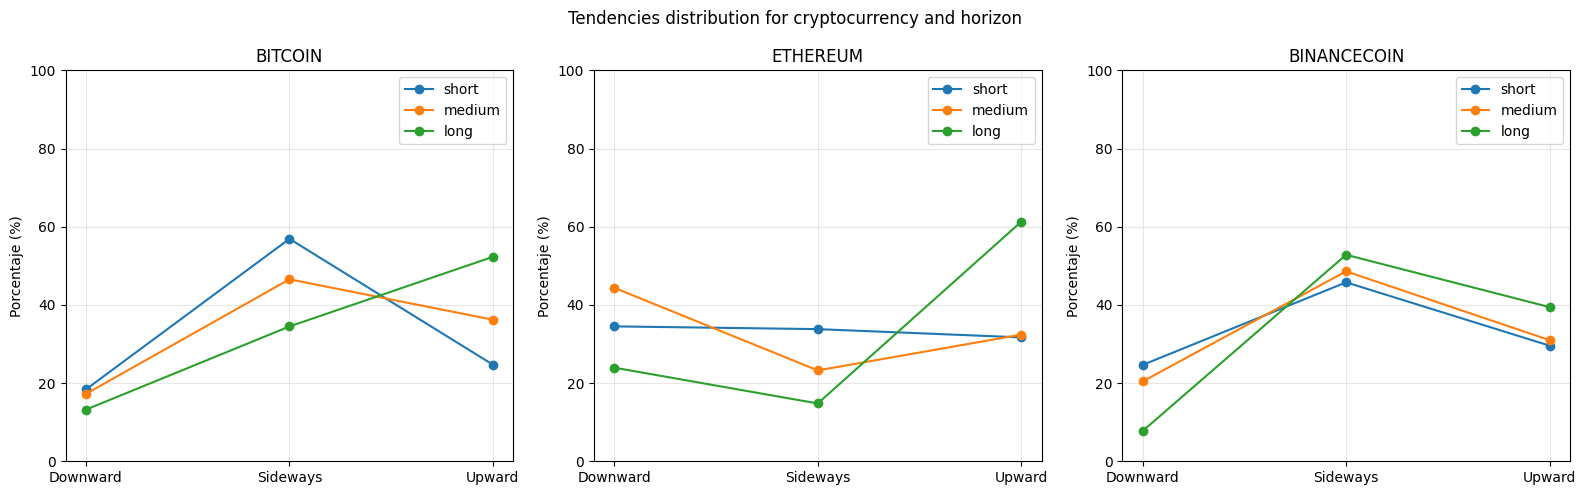

In [140]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16, 5)
)

for ax, crypto in zip(axes, VOLATILE_CRYPTOS):

    crypto_data = target_summary_df[
        target_summary_df["crypto"] == crypto
    ]

    # Usamos las nuevas etiquetas basadas en retorno
    for horizon_name in HORIZONS:
        df = train_target_dfs[crypto]
        col = f"trend_return_3_{horizon_name}"

        percentages = (
            df[col]
            .value_counts(normalize=True)
            .reindex([-1, 0, 1], fill_value=0) * 100
        )

        ax.plot(
            [-1, 0, 1],
            percentages.values,
            marker="o",
            label=horizon_name
        )

    ax.set_title(crypto.upper())
    ax.set_xticks([-1, 0, 1])
    ax.set_xticklabels(["Downward", "Sideways", "Upward"])
    ax.set_ylabel("Porcentaje (%)")
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Tendencies distribution for cryptocurrency and horizon")
plt.tight_layout()
plt.show()

## **15. Stable cryptocurrencies**

### **15.1. Three tendecies classes**

In [141]:
for crypto in STABLE_CRYPTOS:
    df = train_target_dfs[crypto]

    print(f"\n{'=' * 45}")
    print(crypto.upper())
    print(f"{'=' * 45}")

    print("\nPrecio:")
    print(df["price_usd"].describe().round(6))

    print("\nDesviation in comparisson to 1 USD:")
    deviation = (df["price_usd"] - 1) * 100
    print(deviation.describe().round(4))

    print("\nFuture returns:")

    for horizon_name in HORIZONS:
        col = f"future_return_{horizon_name}"

        print(f"\n{horizon_name}:")
        print(
            (df[col].dropna() * 100)
            .describe(
                percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
            )
            .round(4)
        )


TETHER

Precio:
count    174.000000
mean       0.999916
std        0.000202
min        0.999027
25%        0.999928
50%        1.000000
75%        1.000000
max        1.001000
Name: price_usd, dtype: float64

Desviation in comparisson to 1 USD:
count    174.0000
mean      -0.0084
std        0.0202
min       -0.0973
25%       -0.0072
50%        0.0000
75%        0.0000
max        0.1000
Name: price_usd, dtype: float64

Future returns:

short:
count    174.0000
mean      -0.0007
std        0.0268
min       -0.0999
10%       -0.0258
25%       -0.0044
50%        0.0000
75%        0.0012
90%        0.0193
max        0.1018
Name: future_return_short, dtype: float64

medium:
count    174.0000
mean       0.0012
std        0.0287
min       -0.1171
10%       -0.0187
25%       -0.0030
50%        0.0000
75%        0.0033
90%        0.0283
max        0.1000
Name: future_return_medium, dtype: float64

long:
count    174.0000
mean       0.0063
std        0.0305
min       -0.1126
10%       -0.0174
25